[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/04-machine-learning/05_knn-nb-svm.ipynb)

*Machine Learning from Scratch · Notebook 5 of 10*

# k-NN, Naive Bayes & SVM

Three classic classifiers: k-nearest neighbours (vote of the closest examples), Naive Bayes (Bayes' rule with an independence shortcut) and support vector machines (the widest possible margin, plus kernels).

### 👩‍🏫 From your teacher

**The picture to keep in your head:** k-NN asks your neighbours, Naive Bayes counts evidence, and an SVM builds the widest possible road between classes.

**What interviewers really test here:** Scaling for k-NN, the independence assumption, margins and the kernel trick.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. k-nearest neighbours: ask the neighbours *(Basics)*
- [ ] 2. k-NN worked by hand *(Basics)*
- [ ] 3. k-NN for numbers *(Core)*
- [ ] 4. Naive Bayes: Bayes' rule with a shortcut *(Core)*
- [ ] 5. The curse of dimensionality *(Core)*
- [ ] 6. Naive Bayes worked by hand: a spam filter *(Core)*
- [ ] 7. Support vector machines: the widest street *(Advanced)*
- [ ] 8. Kernels: curved boundaries for free *(Advanced)*
- [ ] 9. Gaussian Naive Bayes worked by hand *(Advanced)*
- [ ] 10. The SVM objective, margin and C *(Advanced)*
- [ ] 11. The kernel trick, with real numbers *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### k-nearest neighbours

- **Lazy / instance-based**: stores the data; prediction cost O(n·d) per query (KD-trees / ball trees / approximate nearest neighbour indexes speed this up).
- Hyper-parameters: k, distance metric (Euclidean, Manhattan, Minkowski p, cosine), uniform vs distance weights.
- k = 1: zero training error, high variance. Large k: high bias. As n → ∞, 1-NN error ≤ 2 × Bayes error.
- **Curse of dimensionality**: in high dimensions all points become nearly equidistant; reduce dimensions or select features.
- Requires scaled features; handles multiclass naturally; non-parametric (boundary can be any shape).

### Naive Bayes

ŷ = argmax\_c P(c) Πⱼ P(xⱼ | c), assuming conditional independence of features given the class. Computed as log P(c) + Σ log P(xⱼ | c).



| Variant | P(xⱼ \| c) |
| --- | --- |
| Gaussian | N(xⱼ; μⱼc, σ²ⱼc) |
| Multinomial | θⱼc = (Nⱼc + α)/(N\_c + αV) |
| Bernoulli | θⱼc^xⱼ (1 − θⱼc)^(1−xⱼ) |
| Categorical | smoothed category frequencies |



A generative model: it models how each class generates features. Fast, works with tiny data and many features; independence is usually false, so probabilities are poorly calibrated even when the ranking is good.

### Support vector machines

**Hard margin**: minimise ½‖w‖² subject to yᵢ(w·xᵢ + b) ≥ 1. **Soft margin**: minimise ½‖w‖² + C Σ ξᵢ with yᵢ(w·xᵢ + b) ≥ 1 − ξᵢ, equivalently ½‖w‖² + C Σ max(0, 1 − yᵢ(w·xᵢ + b)) (hinge loss).




- The **dual** problem depends on data only through dot products xᵢ·xⱼ → replace with a kernel K(xᵢ, xⱼ). The solution w = Σ αᵢyᵢxᵢ is non-zero only for support vectors.
- A kernel is valid if its Gram matrix is positive semi-definite (Mercer).
- Training cost grows between O(n²) and O(n³) — use LinearSVC / SGDClassifier for large data.
- Outputs are scores, not probabilities (`probability=True` adds Platt scaling via CV).
- Multiclass via one-vs-one (SVC) or one-vs-rest (LinearSVC). SVR does regression with an ε-insensitive tube.

### Choosing between them

|   | k-NN | Naive Bayes | SVM |
| --- | --- | --- | --- |
| Training | none | very fast | slow on large data (kernels) |
| Prediction | slow on large data | very fast | fast if few support vectors |
| Needs scaling | yes | no | yes |
| Many features | poor | good (text) | good |
| Probabilities | rough | overconfident | extra step |
| Best for | small, low-dimensional data; similarity search | text baselines, tiny data | medium data with clear margins |

---
# Part 2: Lessons, step by step

## Lesson 1: k-nearest neighbours: ask the neighbours

*Level: Basics*

The simplest classifier: to label a new point, find the **k closest** training points and take a **majority vote** (for regression, average their values). There is no training step — the model is the data.




- **Small k** (k = 1): follows every point — wiggly boundary, overfits noise.
- **Large k**: smooth boundary, may underfit. Choose k with validation; use an odd k for two classes to avoid ties.
- **Scale features** first — distance is everything. Optionally weight votes by 1/distance.
- Prediction is slow on big data (compare with every point) and suffers in many dimensions (the "curse of dimensionality").

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

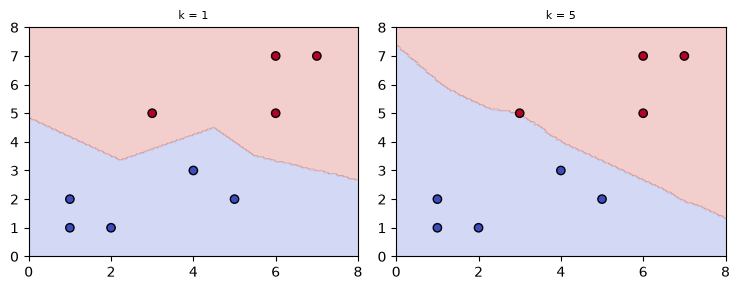

In [2]:
from sklearn.neighbors import KNeighborsClassifier
PTS = np.array([[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3], [3, 5], [5, 2]], dtype=float)
LAB = np.array([0, 0, 0, 1, 1, 1, 0, 1, 0])
def regions(ax, model, title):
    xx, yy = np.meshgrid(np.linspace(0, 8, 150), np.linspace(0, 8, 150))
    zz = model.predict(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    ax.scatter(PTS[:, 0], PTS[:, 1], c=LAB, cmap="coolwarm", edgecolor="black")
    ax.set_title(title, fontsize=8)


def knn_regions():
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 3))
    for ax, k in zip(axes, [1, 5]):
        regions(ax, KNeighborsClassifier(n_neighbors=k).fit(PTS, LAB), f"k = {k}")
    fig.tight_layout()


knn_regions()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q10](#q10), [Q4](#q4), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 2: k-NN worked by hand

*Level: Basics*

Training points: three of class 0 and two of class 1. Classify the new point q = (3, 2) with k = 3.



| Point | Class | Distance to q | Rank |
| --- | --- | --- | --- |
| (2, 1) | 0 | √(1 + 1) = 1.414 | 1 |
| (1, 2) | 0 | √(4 + 0) = 2.000 | 2 |
| (1, 1) | 0 | √(4 + 1) = 2.236 | 3 |
| (6, 5) | 1 | √(9 + 9) = 4.243 |   |
| (7, 7) | 1 | √(16 + 25) = 6.403 |   |



All three nearest points are class 0, so the prediction is **class 0**, with probability 3/3.



#### Why scaling is essential



Compare a person (income 50,000, age 25) with two others:




- (51,000, age **60**): distance ≈ 1,000.6
- (58,000, age **26**): distance ≈ 8,000.0



A person 35 years older counts as far closer, because income's large numbers swamp age. After standardising, both features count fairly.



#### Choosing k



- k = 1 memorises the data: training accuracy is 100% and noise shapes the boundary.
- Very large k approaches the majority class everywhere.
- Plot validation accuracy against k and choose the peak.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [3]:
import math


def knn_by_hand():
    X = np.array([[1, 1], [2, 1], [1, 2], [6, 5], [7, 7]], dtype=float)
    y = np.array([0, 0, 0, 1, 1])
    q = np.array([3.0, 2.0])
    d = np.sqrt(((X - q) ** 2).sum(axis=1))
    nearest = np.argsort(d)[:3]
    votes = y[nearest]
    prediction = np.bincount(votes).argmax()
    near_in_income = math.dist((50000, 25), (51000, 60))
    near_in_age = math.dist((50000, 25), (58000, 26))


knn_by_hand()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 3: k-NN for numbers

*Level: Core*

k-NN regression predicts the average target of the k nearest neighbours. With `weights="distance"`, closer neighbours count more (weight 1/distance), which makes predictions pass through the training points and change smoothly between them.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

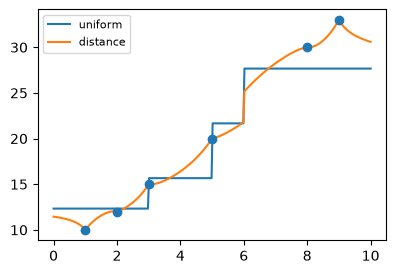

In [4]:
def knn_regression_curve():
    from sklearn.neighbors import KNeighborsRegressor
    x = np.array([1, 2, 3, 5, 8, 9], dtype=float)
    y = np.array([10, 12, 15, 20, 30, 33], dtype=float)
    grid = np.linspace(0, 10, 300).reshape(-1, 1)
    fig, ax = plt.subplots(figsize=(4.5, 3))
    ax.scatter(x, y, zorder=3)
    for weights in ["uniform", "distance"]:
        model = KNeighborsRegressor(n_neighbors=3, weights=weights).fit(x.reshape(-1, 1), y)
        ax.plot(grid, model.predict(grid), label=weights)
    ax.legend(fontsize=8)


knn_regression_curve()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 4: Naive Bayes: Bayes' rule with a shortcut

*Level: Core*

Naive Bayes picks the class with the highest P(class | features) ∝ P(class) × P(features | class). The "naive" shortcut assumes features are independent given the class, so P(features | class) is just a product of one-feature probabilities — easy to learn from little data, and very fast.



| Variant | Features | Each P(feature \| class) |
| --- | --- | --- |
| GaussianNB | numbers | a bell curve with the class's mean and variance |
| MultinomialNB | word counts | (count + α)/(total + α·vocab) — **Laplace smoothing** avoids zero probabilities |
| BernoulliNB | present / absent | share of the class's documents containing the word |



Computed with log-probabilities (sums, not products) to avoid underflow. Great baseline for text and spam filtering; probabilities tend to be over-confident.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

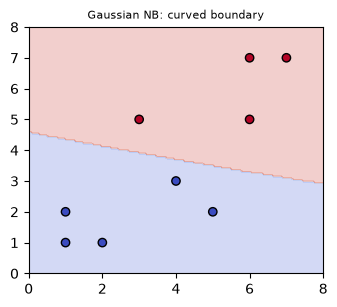

In [5]:
from sklearn.naive_bayes import GaussianNB
PTS = np.array([[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3], [3, 5], [5, 2]], dtype=float)
LAB = np.array([0, 0, 0, 1, 1, 1, 0, 1, 0])
def regions(ax, model, title):
    xx, yy = np.meshgrid(np.linspace(0, 8, 150), np.linspace(0, 8, 150))
    zz = model.predict(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    ax.scatter(PTS[:, 0], PTS[:, 1], c=LAB, cmap="coolwarm", edgecolor="black")
    ax.set_title(title, fontsize=8)


def gnb_regions():
    fig, ax = plt.subplots(figsize=(3.8, 3.2))
    regions(ax, GaussianNB().fit(PTS, LAB), "Gaussian NB: curved boundary")


gnb_regions()

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q6](#q6), [Q7](#q7), [Q16](#q16), [Q13](#q13), [Q17](#q17), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 5: The curse of dimensionality

*Level: Core*

k-NN assumes that nearby points are similar. In many dimensions, that assumption fails: **everything becomes about equally far away.**



The demo draws random points and compares the nearest and farthest distance from a query. As dimensions grow, the ratio approaches 1, so "nearest" stops meaning much.



There's a simple intuition: to cover 10% of the data along one feature you need 10% of its range. To cover 10% of the data in 10 dimensions, you need about 79% of the range of every feature (0.1^(1/10) ≈ 0.79). Your "local" neighbourhood is no longer local.



#### What to do



- Remove irrelevant features, since each one adds pure noise to the distance.
- Reduce dimensions with PCA first.
- Use a model that picks features for itself, such as trees or regularised linear models.
- For text and embeddings, use cosine similarity, which often behaves better.



**Speed:** plain k-NN compares against every row per prediction. KD-trees help in low dimensions, and approximate indexes (HNSW, FAISS) power the vector databases used in RAG systems, which are k-NN at scale.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

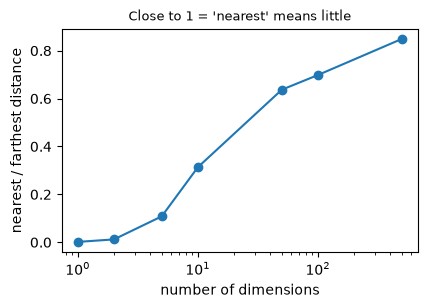

In [6]:
def curse_demo():
    rng = np.random.default_rng(0)
    dims = [1, 2, 5, 10, 50, 100, 500]
    ratios = []
    for d in dims:
        points = rng.uniform(size=(500, d))
        query = rng.uniform(size=d)
        distances = np.sqrt(((points - query) ** 2).sum(axis=1))
        ratios.append(distances.min() / distances.max())
    fig, ax = plt.subplots(figsize=(4.6, 2.9))
    ax.semilogx(dims, ratios, "o-")
    ax.set_xlabel("number of dimensions")
    ax.set_ylabel("nearest / farthest distance")
    ax.set_title("Close to 1 = 'nearest' means little", fontsize=9)


curse_demo()

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 6: Naive Bayes worked by hand: a spam filter

*Level: Core*

Training counts: 40% of emails are spam. Word counts in each class:



| Word | In spam | In ham |
| --- | --- | --- |
| free | 4 | 1 |
| win | 3 | 0 |
| hello | 1 | 5 |
| Total | 8 | 6 |



Classify the email "free win".



#### Step 1: word probabilities with Laplace smoothing



P(word | class) = (count + 1) / (total + vocabulary size), with vocabulary size 3.



|   | Spam | Ham |
| --- | --- | --- |
| P(free) | 5 / 11 = 0.455 | 2 / 9 = 0.222 |
| P(win) | 4 / 11 = 0.364 | 1 / 9 = 0.111 |



Without smoothing, P(win | ham) would be 0, and one unseen word would zero out the whole class.



#### Step 2: multiply prior × likelihoods



- Spam: 0.4 × 0.455 × 0.364 = 0.0661
- Ham: 0.6 × 0.222 × 0.111 = 0.0148



#### Step 3: normalise



P(spam | email) = 0.0661 / (0.0661 + 0.0148) = **0.817**.



**Why "naive"?** It treats "free" and "win" as independent, though they tend to appear together. So it counts the same evidence twice, and its probabilities are overconfident, yet the ranking is often good. Real code adds logs to avoid underflow.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [7]:
def spam_by_hand():
    spam_counts = {"free": 4, "win": 3, "hello": 1}
    ham_counts = {"free": 1, "win": 0, "hello": 5}
    vocab = len(spam_counts)
    spam_total, ham_total = sum(spam_counts.values()), sum(ham_counts.values())
    spam_score, ham_score = 0.4, 0.6
    for word in ["free", "win"]:
        spam_score *= (spam_counts[word] + 1) / (spam_total + vocab)
        ham_score *= (ham_counts[word] + 1) / (ham_total + vocab)
    p_spam = spam_score / (spam_score + ham_score)


spam_by_hand()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q17](#q17), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 7: Support vector machines: the widest street

*Level: Advanced*

Many lines separate two classes. An **SVM** picks the one with the widest **margin** — the widest street with no points on it. Only the points on the edge of the street, the **support vectors**, decide where it goes.




- Margin width = 2/‖w‖, so maximising the margin = minimising ‖w‖ subject to y·(w·x + b) ≥ 1.
- **Soft margin**: real data overlaps, so violations are allowed at a cost — the **hinge loss** max(0, 1 − y·score). **C** trades margin width against violations (large C = fewer violations, narrower margin).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

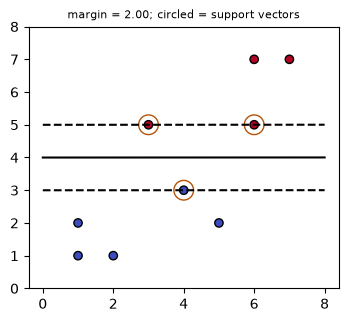

In [8]:
from sklearn.svm import SVC
PTS = np.array([[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3], [3, 5], [5, 2]], dtype=float)
LAB = np.array([0, 0, 0, 1, 1, 1, 0, 1, 0])


def svm_margin():
    model = SVC(kernel="linear", C=10).fit(PTS, LAB)
    w, b = model.coef_[0], model.intercept_[0]
    xs = np.linspace(0, 8, 50)
    fig, ax = plt.subplots(figsize=(4, 3.4))
    ax.scatter(PTS[:, 0], PTS[:, 1], c=LAB, cmap="coolwarm", edgecolor="black")
    for offset, style in [(0, "-"), (1, "--"), (-1, "--")]:
        ax.plot(xs, (offset - b - w[0] * xs) / w[1], style, color="black")
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=200, facecolors="none", edgecolors="#b45309")
    ax.set_ylim(0, 8)
    ax.set_title(f"margin = {2 / np.linalg.norm(w):.2f}; circled = support vectors", fontsize=8)


svm_margin()

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q19](#q19), [Q14](#q14), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 8: Kernels: curved boundaries for free

*Level: Advanced*

When classes aren't linearly separable, map points to a bigger space where they are (e.g. add x², xy, y²). The **kernel trick**: SVMs only ever need dot products between points, and a **kernel** computes the dot product in the big space directly from the original points — without building it.



| Kernel | K(x, z) |
| --- | --- |
| Linear | x·z |
| Polynomial | (γ x·z + r)ᵈ |
| RBF (Gaussian) | exp(−γ‖x − z‖²) — the default; γ controls how local the boundary is |



Tune C and γ together with cross-validation, and always scale features.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

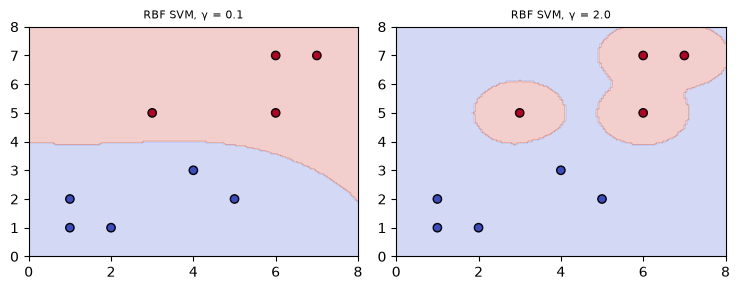

In [9]:
from sklearn.svm import SVC
PTS = np.array([[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3], [3, 5], [5, 2]], dtype=float)
LAB = np.array([0, 0, 0, 1, 1, 1, 0, 1, 0])
def regions(ax, model, title):
    xx, yy = np.meshgrid(np.linspace(0, 8, 150), np.linspace(0, 8, 150))
    zz = model.predict(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    ax.scatter(PTS[:, 0], PTS[:, 1], c=LAB, cmap="coolwarm", edgecolor="black")
    ax.set_title(title, fontsize=8)


def rbf_regions():
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 3))
    for ax, gamma in zip(axes, [0.1, 2.0]):
        regions(ax, SVC(kernel="rbf", gamma=gamma, C=10).fit(PTS, LAB), f"RBF SVM, γ = {gamma}")
    fig.tight_layout()


rbf_regions()

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 9: Gaussian Naive Bayes worked by hand

*Level: Advanced*

Guess group from height. Group A: 170, 175, 180 (mean 175). Group B: 155, 160, 165 (mean 160). Both have variance 16.67 and the priors are equal. Who is a person of height 168?



Use the bell-curve height f(x) = e^(−(x − μ)² / 2σ²) / √(2πσ²):



| Group | Distance from mean | f(168) |
| --- | --- | --- |
| A | 7 | 0.0225 |
| B | 8 | 0.0143 |



P(A | 168) = 0.0225 / (0.0225 + 0.0143) = **0.611**. It's closer to A's mean, though not by much, so the model is only mildly confident.



With more features, multiply each feature's bell-curve value together. When variances differ between classes the boundary curves, which is what you saw in the earlier chart.



#### Generative vs discriminative



Naive Bayes is **generative**: it models how each class produces data, P(x | class). Logistic regression is **discriminative**: it models P(class | x) directly. Naive Bayes often wins with very little data, and logistic regression usually wins once there's more.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

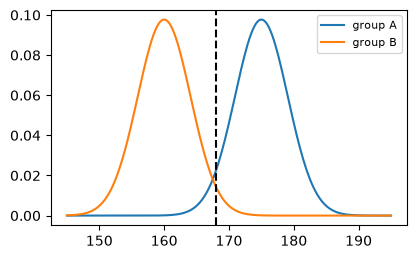

In [10]:
import math


def gaussian_nb_by_hand():
    a, b = np.array([170.0, 175, 180]), np.array([155.0, 160, 165])

    def bell(x, group):
        mean, var = group.mean(), group.var()
        return math.exp(-(x - mean) ** 2 / (2 * var)) / math.sqrt(2 * math.pi * var)

    height_a = bell(168, a)
    height_b = bell(168, b)
    p_a = height_a / (height_a + height_b)
    grid = np.linspace(145, 195, 200)
    fig, ax = plt.subplots(figsize=(4.6, 2.8))
    ax.plot(grid, [bell(v, a) for v in grid], label="group A")
    ax.plot(grid, [bell(v, b) for v in grid], label="group B")
    ax.axvline(168, color="black", ls="--")
    ax.legend(fontsize=8)


gaussian_nb_by_hand()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. bell() returns 0.022468433922546174
2. bell() returns 0.014326505991869068
3. bell() returns 1.8366850019098434e-13
4. bell() returns 2.881554000990412e-13
5. bell() returns 4.503745410904005e-13
6. bell() returns 7.012548680744217e-13
7. bell() returns 1.0877596187564173e-12
8. bell() returns 1.6809119403829479e-12
9. bell() returns 2.5876883988162667e-12
10. bell() returns 3.968569424246058e-12
11. bell() returns 6.063326738649234e-12
12. bell() returns 9.228751427748961e-12
13. bell() returns 1.399361470160765e-11
14. bell() returns 2.11383878402044e-11
15. bell() returns 3.181037571413459e-11
16. bell() returns 4.768927520810074e-11
17. bell() returns 7.122420855303896e-11
18. bell() returns 1.059716090880623e-10
19. bell() returns 1.5707476267059618e-10
20. bell() returns 2.3194140430921993e-10
21. bell() returns 3.4119694905590974e-10

</details>


**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q7](#q7), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 10: The SVM objective, margin and C

*Level: Advanced*

#### Why the margin is 2 / ‖w‖



The boundary is w·x + b = 0, and the street's edges are w·x + b = ±1. The distance from a point to the boundary is |w·x + b| / ‖w‖, so each edge is 1 / ‖w‖ away and the street is 2 / ‖w‖ wide. A wider street means a smaller ‖w‖.



#### The objective has two competing goals



**minimise ½‖w‖² + C · Σ hinge losses**



#### Hinge loss, worked by hand: max(0, 1 − y·score)



| y | Score | Loss | Meaning |
| --- | --- | --- | --- |
| +1 | 2.0 | 0 | correct, outside the street |
| +1 | 0.5 | 0.5 | correct, but inside the street |
| +1 | −0.3 | 1.3 | wrong side |
| −1 | −1.5 | 0 | correct, outside the street |



Points with zero loss have no effect on the model, and that's why only support vectors matter.



#### The role of C



- **Small C:** wide street, tolerates mistakes, stronger regularisation.
- **Large C:** narrow street, tries to classify every point, and may overfit.



Note that C works like logistic regression's C: bigger means *less* regularisation.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

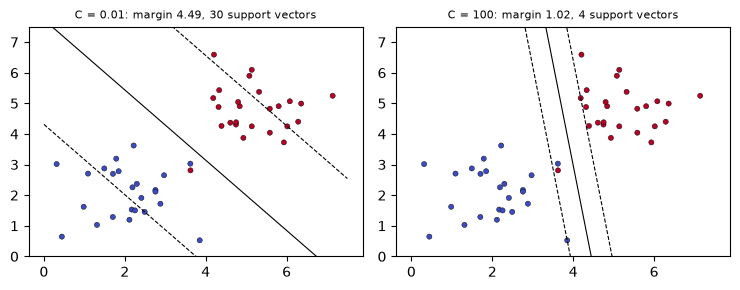

In [11]:
from sklearn.svm import SVC


def c_effect():
    rng = np.random.default_rng(2)
    X = np.vstack([rng.normal([2, 2], 0.9, (25, 2)), rng.normal([5, 5], 0.9, (25, 2))])
    y = np.r_[np.zeros(25, dtype=int), np.ones(25, dtype=int)]
    xs = np.linspace(0, 7.5, 30)
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 3))
    for ax, c in zip(axes, [0.01, 100]):
        model = SVC(kernel="linear", C=c).fit(X, y)
        w, b = model.coef_[0], model.intercept_[0]
        ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=14, edgecolor="black", linewidth=0.3)
        for offset, style in [(0, "-"), (1, "--"), (-1, "--")]:
            ax.plot(xs, (offset - b - w[0] * xs) / w[1], style, color="black", linewidth=0.8)
        ax.set_ylim(0, 7.5)
        ax.set_title(f"C = {c}: margin {2 / np.linalg.norm(w):.2f}, {len(model.support_)} support vectors", fontsize=8)
    fig.tight_layout()


c_effect()

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q14](#q14), [Q15](#q15), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 11: The kernel trick, with real numbers

*Level: Advanced*

Take x = (1, 2) and z = (3, 1). We want the dot product after mapping into a bigger space.



#### The long way



φ(v) = (1, √2·v₁, √2·v₂, v₁², √2·v₁v₂, v₂²), so



- φ(x) = (1, 1.414, 2.828, 1, 2.828, 4)
- φ(z) = (1, 4.243, 1.414, 9, 4.243, 1)



Their dot product is 1 + 6 + 4 + 9 + 12 + 4 = **36**.



#### The shortcut



x·z = 3 + 2 = 5, then (x·z + 1)² = 6² = **36**. Same answer, and we never built the six-dimensional vectors. That's the trick, and it means even infinite-dimensional mappings can be used.



#### The RBF kernel: exp(−γ‖x − z‖²)



| γ | Squared distance 1 | Squared distance 25 |
| --- | --- | --- |
| 0.01 | 0.990 | 0.779 |
| 0.1 | 0.905 | 0.082 |
| 1 | 0.368 | 0.000 |



Large γ means similarity fades fast, so each point influences only its neighbourhood, giving a wiggly boundary that can overfit. Small γ gives a smooth boundary.



**Tuning recipe:** scale features, then grid-search C and γ together on log scales.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [12]:
import math


def kernel_numbers():
    x, z = np.array([1.0, 2.0]), np.array([3.0, 1.0])
    root2 = math.sqrt(2)
    phi_x = np.array([1, root2 * x[0], root2 * x[1], x[0] ** 2, root2 * x[0] * x[1], x[1] ** 2])
    phi_z = np.array([1, root2 * z[0], root2 * z[1], z[0] ** 2, root2 * z[0] * z[1], z[1] ** 2])
    long_way = phi_x @ phi_z
    shortcut = (x @ z + 1) ** 2
    rbf_near = {g: round(math.exp(-g * 1), 3) for g in [0.01, 0.1, 1]}
    rbf_far = {g: round(math.exp(-g * 25), 3) for g in [0.01, 0.1, 1]}


kernel_numbers()

**✏️ Your turn:** you now have what you need for [Q20](#q20), [Q9](#q9). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [13]:
from sklearn.metrics.pairwise import euclidean_distances, rbf_kernel, polynomial_kernel

import math

from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

from sklearn.metrics import hinge_loss, accuracy_score

from sklearn.svm import SVC, LinearSVC


<a id="q1"></a>
### Q1. Distances to Every Training Point

🟢 Warm-up · *The heart of k-NN*

Return the Euclidean distance from the query to each training point, rounded to 4 decimals.

**Examples**

- `X = [[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], q = [3, 3]` → `[2.8284, 2.2361, 2.2361, 3.6056, 5.6569, 5.0, 1.0]`

In [ ]:
def distances(X, q):
    """
    Return the Euclidean distance from the query to each training point, rounded
    to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(distances, [
    (([[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], [3, 3]), [2.8284, 2.2361, 2.2361, 3.6056, 5.6569, 5.0, 1.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Pythagoras for each point.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`euclidean_distances(X, [q])`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Pythagoras for each point.

```python
def distances(X, q):
    return [round(math.sqrt(sum((a - b) ** 2 for a, b in zip(p, q))), 4) for p in X]
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `euclidean_distances(X, [q])`.

```python
def distances(X, q):
    return euclidean_distances(X, [q]).ravel().round(4)
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Pythagoras for each point. That costs O(n·d) time and O(n) space."

"I can do better: `euclidean_distances(X, [q])`. That's O(n·d) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/distances-to-every-training-point)

<a id="q2"></a>
### Q2. Classify One Point With k-NN

🟢 Warm-up · *Majority vote of the k closest*

Return the majority label among the k nearest training points to q.

**Examples**

- `X = [[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], y = [0, 0, 0, 1, 1, 1, 0], q = [3, 3], k = 3` → `0`
- `X = [[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], y = [0, 0, 0, 1, 1, 1, 0], q = [5, 5], k = 3` → `1`

In [ ]:
def knn_one(X, y, q, k):
    """
    Return the majority label among the k nearest training points to q.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(knn_one, [
    (([[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], [0, 0, 0, 1, 1, 1, 0], [3, 3], 3), 0),
    (([[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], [0, 0, 0, 1, 1, 1, 0], [5, 5], 3), 1),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort the training points by distance, take k, count the labels.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`KNeighborsClassifier(n_neighbors=k).fit(X, y).predict([q])`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Sort the training points by distance, take k, count the labels.

```python
def knn_one(X, y, q, k):
    order = sorted(range(len(X)), key=lambda i: sum((a - b) ** 2 for a, b in zip(X[i], q)))
    votes = {}
    for i in order[:k]:
        votes[y[i]] = votes.get(y[i], 0) + 1
    best = max(votes.values())
    return min(label for label, v in votes.items() if v == best)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `KNeighborsClassifier(n_neighbors=k).fit(X, y).predict([q])`.

```python
def knn_one(X, y, q, k):
    return KNeighborsClassifier(n_neighbors=k).fit(X, y).predict([q])[0]
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort the training points by distance, take k, count the labels. That costs O(n log n) time and O(n) space."

"I can do better: `KNeighborsClassifier(n_neighbors=k).fit(X, y).predict([q])`. That's O(n·d) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/classify-one-point-with-k-nn)

<a id="q3"></a>
### Q3. k-NN Regression

🟢 Warm-up · *Average of the neighbours*

Predict a number for q as the mean target of its k nearest neighbours (one feature), rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 5, 8, 9], y = [10, 12, 15, 20, 30, 33], q = 4.1, k = 3` → `15.6667`

In [ ]:
def knn_regress(x, y, q, k):
    """
    Predict a number for q as the mean target of its k nearest neighbours (one
    feature), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(knn_regress, [
    (([1, 2, 3, 5, 8, 9], [10, 12, 15, 20, 30, 33], 4.1, 3), 15.6667),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort by |x − q|, average the first k targets.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`KNeighborsRegressor(n_neighbors=k)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Sort by |x − q|, average the first k targets.

```python
def knn_regress(x, y, q, k):
    order = sorted(range(len(x)), key=lambda i: abs(x[i] - q))
    return round(sum(y[i] for i in order[:k]) / k, 4)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `KNeighborsRegressor(n_neighbors=k)`.

```python
def knn_regress(x, y, q, k):
    model = KNeighborsRegressor(n_neighbors=k).fit(np.array(x).reshape(-1, 1), y)
    return round(model.predict([[q]])[0], 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort by |x − q|, average the first k targets. That costs O(n log n) time and O(n) space."

"I can do better: `KNeighborsRegressor(n_neighbors=k)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/k-nn-regression)

<a id="q4"></a>
### Q4. k-NN With Manhattan Distance

🟢 Warm-up · *Changing the metric*

Classify q by majority vote of its k nearest points using Manhattan distance.

**Examples**

- `X = [[0, 0], [3, 0], [0, 3], [2, 2]], y = ['A', 'B', 'B', 'A'], q = [2.1, 0.5], k = 1` → `'B'`

In [ ]:
def knn_manhattan(X, y, q, k):
    """
    Classify q by majority vote of its k nearest points using Manhattan
    distance.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(knn_manhattan, [
    (([[0, 0], [3, 0], [0, 3], [2, 2]], ['A', 'B', 'B', 'A'], [2.1, 0.5], 1), 'B'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort by Σ|differences|, vote.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`KNeighborsClassifier(metric='manhattan')`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Sort by Σ|differences|, vote.

```python
def knn_manhattan(X, y, q, k):
    order = sorted(range(len(X)), key=lambda i: sum(abs(a - b) for a, b in zip(X[i], q)))
    labels = [y[i] for i in order[:k]]
    return max(sorted(set(labels)), key=labels.count)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `KNeighborsClassifier(metric='manhattan')`.

```python
def knn_manhattan(X, y, q, k):
    return KNeighborsClassifier(n_neighbors=k, metric="manhattan").fit(X, y).predict([q])[0]
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort by Σ|differences|, vote. That costs O(n log n) time and O(n) space."

"I can do better: `KNeighborsClassifier(metric='manhattan')`. That's O(n·d) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/k-nn-with-manhattan-distance)

<a id="q5"></a>
### Q5. Class Priors

🟢 Warm-up · *P(class) before seeing features*

Return each class's share of the training labels (sorted classes), rounded to 4 decimals.

**Examples**

- `y = [0, 0, 0, 1, 1, 1, 0]` → `[0.5714, 0.4286]`
- `y = ['spam', 'ham', 'ham', 'ham']` → `[0.75, 0.25]`

In [ ]:
def priors(y):
    """
    Return each class's share of the training labels (sorted classes), rounded
    to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(priors, [
    (([0, 0, 0, 1, 1, 1, 0],), [0.5714, 0.4286]),
    ((['spam', 'ham', 'ham', 'ham'],), [0.75, 0.25]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count and divide.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`GaussianNB().fit(...).class_prior_`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count and divide.

```python
def priors(y):
    return [round(y.count(c) / len(y), 4) for c in sorted(set(y))]
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `GaussianNB().fit(...).class_prior_`.

```python
def priors(y):
    return GaussianNB().fit(np.zeros((len(y), 1)), y).class_prior_.round(4)
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count and divide. That costs O(n) time and O(k) space."

"I can do better: `GaussianNB().fit(...).class_prior_`. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/class-priors)

<a id="q6"></a>
### Q6. Gaussian Naive Bayes: Means per Class

🟢 Warm-up · *What GaussianNB learns*

Return the mean of each feature within each class (rows = sorted classes), rounded to 4 decimals.

**Examples**

- `X = [[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], y = [0, 0, 0, 1, 1, 1, 0]` → `[[2.0, 1.75], [6.3333, 6.3333]]`

In [ ]:
def class_means(X, y):
    """
    Return the mean of each feature within each class (rows = sorted classes),
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(class_means, [
    (([[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], [0, 0, 0, 1, 1, 1, 0]), [[2.0, 1.75], [6.3333, 6.3333]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Group rows by class and average each column.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`GaussianNB().fit(X, y).theta_`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Group rows by class and average each column.

```python
def class_means(X, y):
    out = []
    for c in sorted(set(y)):
        rows = [r for r, label in zip(X, y) if label == c]
        out.append([round(sum(r[j] for r in rows) / len(rows), 4) for j in range(len(X[0]))])
    return out
```

**Cost:** O(n·d) time, O(k·d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `GaussianNB().fit(X, y).theta_`.

```python
def class_means(X, y):
    return GaussianNB().fit(X, y).theta_.round(4)
```

**Cost:** O(n·d) time, O(k·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Group rows by class and average each column. That costs O(n·d) time and O(k·d) space."

"I can do better: `GaussianNB().fit(X, y).theta_`. That's O(n·d) time and O(k·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/gaussian-naive-bayes-means-per-class)

<a id="q7"></a>
### Q7. Gaussian Naive Bayes: Variances per Class

🟢 Warm-up · *The width of each bell curve*

Return the (population) variance of each feature within each class, rows = sorted classes, rounded to 4 decimals.

**Examples**

- `X = [[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], y = [0, 0, 0, 1, 1, 1, 0]` → `[[1.5, 0.6875], [0.2222, 0.8889]]`

In [ ]:
def class_vars(X, y):
    """
    Return the (population) variance of each feature within each class, rows =
    sorted classes, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(class_vars, [
    (([[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], [0, 0, 0, 1, 1, 1, 0]), [[1.5, 0.6875], [0.2222, 0.8889]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Group by class; average squared distance from the class mean.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`GaussianNB().fit(X, y).var_` (it adds a tiny ε for stability).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Group by class; average squared distance from the class mean.

```python
def class_vars(X, y):
    out = []
    for c in sorted(set(y)):
        rows = [r for r, label in zip(X, y) if label == c]
        row_out = []
        for j in range(len(X[0])):
            mean = sum(r[j] for r in rows) / len(rows)
            row_out.append(round(sum((r[j] - mean) ** 2 for r in rows) / len(rows), 4))
        out.append(row_out)
    return out
```

**Cost:** O(n·d) time, O(k·d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `GaussianNB().fit(X, y).var_` (it adds a tiny ε for stability).

```python
def class_vars(X, y):
    return GaussianNB().fit(X, y).var_.round(4)
```

**Cost:** O(n·d) time, O(k·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Group by class; average squared distance from the class mean. That costs O(n·d) time and O(k·d) space."

"I can do better: `GaussianNB().fit(X, y).var_` (it adds a tiny ε for stability). That's O(n·d) time and O(k·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/gaussian-naive-bayes-variances-per-class)

<a id="q8"></a>
### Q8. Hinge Loss

🟢 Warm-up · *The SVM's loss*

Labels are ±1 and scores are the model's raw outputs. Return mean max(0, 1 − y·score), rounded to 4 decimals.

**Examples**

- `y = [1, -1, 1, -1], scores = [2.0, -0.5, 0.3, 1.2]` → `0.85`

In [ ]:
def hinge(y, scores):
    """
    Labels are ±1 and scores are the model's raw outputs. Return mean max(0, 1 −
    y·score), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(hinge, [
    (([1, -1, 1, -1], [2.0, -0.5, 0.3, 1.2]), 0.85),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop with max(0, …).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`hinge_loss(y, scores)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop with max(0, …).

```python
def hinge(y, scores):
    return round(sum(max(0, 1 - a * s) for a, s in zip(y, scores)) / len(y), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `hinge_loss(y, scores)`.

```python
def hinge(y, scores):
    return round(hinge_loss(y, scores), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop with max(0, …). That costs O(n) time and O(1) space."

"I can do better: `hinge_loss(y, scores)`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/hinge-loss)

<a id="q9"></a>
### Q9. RBF Kernel

🟢 Warm-up · *Similarity that fades with distance*

Return the matrix K[i][j] = exp(−γ·‖xᵢ − xⱼ‖²), rounded to 4 decimals.

**Examples**

- `X = [[0, 0], [1, 0], [3, 4]], gamma = 0.5` → `[[1.0, 0.6065, 0.0], [0.6065, 1.0, 0.0], [0.0, 0.0, 1.0]]`

In [ ]:
def rbf(X, gamma):
    """
    Return the matrix K[i][j] = exp(−γ·‖xᵢ − xⱼ‖²), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rbf, [
    (([[0, 0], [1, 0], [3, 4]], 0.5), [[1.0, 0.6065, 0.0], [0.6065, 1.0, 0.0], [0.0, 0.0, 1.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Double loop over pairs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`rbf_kernel(X, gamma=γ)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Double loop over pairs.

```python
def rbf(X, gamma):
    return [[round(math.exp(-gamma * sum((a - b) ** 2 for a, b in zip(p, q))), 4) for q in X] for p in X]
```

**Cost:** O(n²·d) time, O(n²) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `rbf_kernel(X, gamma=γ)`.

```python
def rbf(X, gamma):
    return rbf_kernel(X, gamma=gamma).round(4)
```

**Cost:** O(n²·d) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Double loop over pairs. That costs O(n²·d) time and O(n²) space."

"I can do better: `rbf_kernel(X, gamma=γ)`. That's O(n²·d) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/rbf-kernel)

<a id="q10"></a>
### Q10. k-NN for Many Points

🟡 Interview standard · *Predicting a whole test set*

Predict the label of every query point with k-NN.

**Examples**

- `X = [[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], y = [0, 0, 0, 1, 1, 1, 0], queries = [[0, 0], [8, 8], [5, 4], [3, 2]], k = 3` → `[0, 1, 1, 0]`

In [ ]:
def knn_many(X, y, queries, k):
    """
    Predict the label of every query point with k-NN.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(knn_many, [
    (([[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], [0, 0, 0, 1, 1, 1, 0], [[0, 0], [8, 8], [5, 4], [3, 2]], 3), [0, 1, 1, 0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Repeat the single-point vote for each query.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`predict` on all queries at once.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Repeat the single-point vote for each query.

```python
def knn_many(X, y, queries, k):
    out = []
    for q in queries:
        order = sorted(range(len(X)), key=lambda i: sum((a - b) ** 2 for a, b in zip(X[i], q)))
        labels = [y[i] for i in order[:k]]
        out.append(max(sorted(set(labels)), key=labels.count))
    return out
```

**Cost:** O(m·n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `predict` on all queries at once.

```python
def knn_many(X, y, queries, k):
    return KNeighborsClassifier(n_neighbors=k).fit(X, y).predict(queries)
```

**Cost:** O(m·n·d) time, O(m·n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Repeat the single-point vote for each query. That costs O(m·n log n) time and O(n) space."

"I can do better: `predict` on all queries at once. That's O(m·n·d) time and O(m·n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/k-nn-for-many-points)

<a id="q11"></a>
### Q11. Distance-Weighted k-NN

🟡 Interview standard · *Closer neighbours count more*

Predict q as the weighted mean of its k nearest targets with weights 1/distance, rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 5, 8, 9], y = [10, 12, 15, 20, 30, 33], q = 4.1, k = 3` → `16.6532`

In [ ]:
def knn_weighted(x, y, q, k):
    """
    Predict q as the weighted mean of its k nearest targets with weights
    1/distance, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(knn_weighted, [
    (([1, 2, 3, 5, 8, 9], [10, 12, 15, 20, 30, 33], 4.1, 3), 16.6532),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Weights 1/|x − q| for the k nearest, then Σw·y / Σw.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`KNeighborsRegressor(n_neighbors=k, weights='distance')`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Weights 1/|x − q| for the k nearest, then Σw·y / Σw.

```python
def knn_weighted(x, y, q, k):
    order = sorted(range(len(x)), key=lambda i: abs(x[i] - q))[:k]
    weights = [1 / abs(x[i] - q) for i in order]
    return round(sum(w * y[i] for w, i in zip(weights, order)) / sum(weights), 4)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `KNeighborsRegressor(n_neighbors=k, weights='distance')`.

```python
def knn_weighted(x, y, q, k):
    model = KNeighborsRegressor(n_neighbors=k, weights="distance").fit(np.array(x).reshape(-1, 1), y)
    return round(model.predict([[q]])[0], 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Weights 1/|x − q| for the k nearest, then Σw·y / Σw. That costs O(n log n) time and O(n) space."

"I can do better: `KNeighborsRegressor(n_neighbors=k, weights='distance')`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/distance-weighted-k-nn)

<a id="q12"></a>
### Q12. Choose k on a Validation Set

🟡 Interview standard · *Tuning k*

For each k in ks, train k-NN on (X, y) and measure accuracy on (Xv, yv). Return the k with the best accuracy (smallest k on ties).

**Examples**

- `X = [[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], y = [0, 0, 0, 1, 1, 1, 0], Xv = [[2, 2], [6, 6], [4, 4], [5, 5], [3, 4]], yv = [0, 1, 0, 1, 1], ks = [1, 3, 5]` → `1`

In [ ]:
def choose_k(X, y, Xv, yv, ks):
    """
    For each k in ks, train k-NN on (X, y) and measure accuracy on (Xv, yv).
    Return the k with the best accuracy (smallest k on ties).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(choose_k, [
    (([[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], [0, 0, 0, 1, 1, 1, 0], [[2, 2], [6, 6], [4, 4], [5, 5], [3, 4]], [0, 1, 0, 1, 1], [1, 3, 5]), 1),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over k; hand-written k-NN; count correct validation predictions.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Fit `KNeighborsClassifier` per k and use `accuracy_score`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop over k; hand-written k-NN; count correct validation predictions.

```python
def choose_k(X, y, Xv, yv, ks):
    best_k, best_acc = None, -1
    for k in ks:
        correct = 0
        for q, truth in zip(Xv, yv):
            order = sorted(range(len(X)), key=lambda i: sum((a - b) ** 2 for a, b in zip(X[i], q)))
            labels = [y[i] for i in order[:k]]
            pred = max(sorted(set(labels)), key=labels.count)
            correct += pred == truth
        acc = correct / len(yv)
        if acc > best_acc:
            best_k, best_acc = k, acc
    return best_k
```

**Cost:** O(K·m·n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Fit `KNeighborsClassifier` per k and use `accuracy_score`.

```python
def choose_k(X, y, Xv, yv, ks):
    scores = [accuracy_score(yv, KNeighborsClassifier(n_neighbors=k).fit(X, y).predict(Xv)) for k in ks]
    return ks[int(np.argmax(scores))]
```

**Cost:** O(K·m·n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over k; hand-written k-NN; count correct validation predictions. That costs O(K·m·n log n) time and O(n) space."

"I can do better: Fit `KNeighborsClassifier` per k and use `accuracy_score`. That's O(K·m·n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/choose-k-on-a-validation-set)

<a id="q13"></a>
### Q13. Word Probabilities With Laplace Smoothing

🟡 Interview standard · *Never multiply by zero*

Rows are word counts per document. For each class return P(word | class) = (count + α)/(total + α·vocab), α = 1, rounded to 4 decimals.

**Examples**

- `X = [[2, 1, 0, 0], [3, 0, 1, 0], [0, 0, 2, 3], [0, 1, 1, 4]], y = ['sport', 'sport', 'tech', 'tech']` → `[[0.5455, 0.1818, 0.1818, 0.0909], [0.0667, 0.1333, 0.2667, 0.5333]]`

In [ ]:
def word_probs(X, y):
    """
    Rows are word counts per document. For each class return P(word | class) =
    (count + α)/(total + α·vocab), α = 1, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(word_probs, [
    (([[2, 1, 0, 0], [3, 0, 1, 0], [0, 0, 2, 3], [0, 1, 1, 4]], ['sport', 'sport', 'tech', 'tech']), [[0.5455, 0.1818, 0.1818, 0.0909], [0.0667, 0.1333, 0.2667, 0.5333]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sum the counts of each class's documents, add α, divide.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.exp(MultinomialNB(alpha=1).fit(X, y).feature_log_prob_)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Sum the counts of each class's documents, add α, divide.

```python
def word_probs(X, y):
    out = []
    for c in sorted(set(y)):
        totals = [sum(r[j] for r, label in zip(X, y) if label == c) for j in range(len(X[0]))]
        denom = sum(totals) + len(totals)
        out.append([round((t + 1) / denom, 4) for t in totals])
    return out
```

**Cost:** O(n·V) time, O(k·V) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `np.exp(MultinomialNB(alpha=1).fit(X, y).feature_log_prob_)`.

```python
def word_probs(X, y):
    return np.exp(MultinomialNB(alpha=1.0).fit(X, y).feature_log_prob_).round(4)
```

**Cost:** O(n·V) time, O(k·V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sum the counts of each class's documents, add α, divide. That costs O(n·V) time and O(k·V) space."

"I can do better: `np.exp(MultinomialNB(alpha=1).fit(X, y).feature_log_prob_)`. That's O(n·V) time and O(k·V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/word-probabilities-with-laplace-smoothing)

<a id="q14"></a>
### Q14. Margin Width

🟡 Interview standard · *2 / ‖w‖*

For the SVM trained on one positive point p and one negative point n, return the width of the margin, rounded to 4 decimals.

**Examples**

- `p = [3, 3], n = [1, 1]` → `2.8284`
- `p = [4, 0], n = [0, 2]` → `4.4721`

In [ ]:
def margin_width(p, n):
    """
    For the SVM trained on one positive point p and one negative point n, return
    the width of the margin, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(margin_width, [
    (([3, 3], [1, 1]), 2.8284),
    (([4, 0], [0, 2]), 4.4721),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

The margin is the full distance between the two points: ‖p − n‖.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Fit `SVC` and compute 2/‖w‖.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** The margin is the full distance between the two points: ‖p − n‖.

```python
def margin_width(p, n):
    return round(math.sqrt(sum((a - b) ** 2 for a, b in zip(p, n))), 4)
```

**Cost:** O(d) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Fit `SVC` and compute 2/‖w‖.

```python
def margin_width(p, n):
    model = SVC(kernel="linear", C=1e6).fit([p, n], [1, -1])
    return round(2 / np.linalg.norm(model.coef_[0]), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: The margin is the full distance between the two points: ‖p − n‖. That costs O(d) time and O(1) space."

"I can do better: Fit `SVC` and compute 2/‖w‖. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/margin-width)

<a id="q15"></a>
### Q15. Points Inside the Margin

🟡 Interview standard · *Support vectors and violations*

A linear SVM has weights w and bias b. For each point return (predicted label ±1, True if |w·x + b| &lt; 1).

**Examples**

- `X = [[2, 2], [0, 0], [1, 0.8], [3, 0]], w = [1.0, 1.0], b = -2.0` → `[(1, False), (-1, False), (-1, True), (1, False)]`

In [ ]:
def margin_check(X, w, b):
    """
    A linear SVM has weights w and bias b. For each point return (predicted
    label ±1, True if |w·x + b| < 1).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(margin_check, [
    (([[2, 2], [0, 0], [1, 0.8], [3, 0]], [1.0, 1.0], -2.0), [(1, False), (-1, False), (-1, True), (1, False)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Score each point by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A `LinearSVC` holding those coefficients: `predict` and `decision_function`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Score each point by hand.

```python
def margin_check(X, w, b):
    out = []
    for row in X:
        z = b + sum(wi * xi for wi, xi in zip(w, row))
        out.append((1 if z > 0 else -1, abs(z) < 1))
    return out
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** A `LinearSVC` holding those coefficients: `predict` and `decision_function`.

```python
def margin_check(X, w, b):
    model = LinearSVC()
    model.coef_, model.intercept_, model.classes_ = np.array([w]), np.array([b]), np.array([-1, 1])
    z = model.decision_function(np.array(X, dtype=float))
    return [(int(p), bool(abs(s) < 1)) for p, s in zip(model.predict(np.array(X, dtype=float)), z)]
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Score each point by hand. That costs O(n·d) time and O(n) space."

"I can do better: A `LinearSVC` holding those coefficients: `predict` and `decision_function`. That's O(n·d) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/points-inside-the-margin)

<a id="q16"></a>
### Q16. Gaussian Naive Bayes: Predict Probabilities

🔴 Stretch · *Bayes' rule with bell curves*

Fit Gaussian NB and return P(class | q) for each class, rounded to 4 decimals.

**Examples**

- `X = [[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], y = [0, 0, 0, 1, 1, 1, 0], q = [4, 4]` → `[0.9999, 0.0001]`
- `X = [[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], y = [0, 0, 0, 1, 1, 1, 0], q = [2, 2]` → `[1.0, 0.0]`

In [ ]:
def gnb_proba(X, y, q):
    """
    Fit Gaussian NB and return P(class | q) for each class, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(gnb_proba, [
    (([[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], [0, 0, 0, 1, 1, 1, 0], [4, 4]), [0.9999, 0.0001]),
    (([[1, 1], [2, 1], [1, 2], [6, 5], [7, 7], [6, 7], [4, 3]], [0, 0, 0, 1, 1, 1, 0], [2, 2]), [1.0, 0.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Per class: prior × Π normal-density(feature; class mean, class variance + tiny ε), then normalise.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`GaussianNB().fit(X, y).predict_proba([q])`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Per class: prior × Π normal-density(feature; class mean, class variance + tiny ε), then normalise.

```python
def gnb_proba(X, y, q):
    d = len(X[0])
    all_var = [sum((r[j] - sum(t[j] for t in X) / len(X)) ** 2 for r in X) / len(X) for j in range(d)]
    eps = 1e-9 * max(all_var)
    scores = []
    for c in sorted(set(y)):
        rows = [r for r, label in zip(X, y) if label == c]
        log_p = math.log(len(rows) / len(X))
        for j in range(d):
            mean = sum(r[j] for r in rows) / len(rows)
            var = sum((r[j] - mean) ** 2 for r in rows) / len(rows) + eps
            log_p += -0.5 * math.log(2 * math.pi * var) - (q[j] - mean) ** 2 / (2 * var)
        scores.append(log_p)
    top = max(scores)
    exps = [math.exp(s - top) for s in scores]
    return [round(e / sum(exps), 4) for e in exps]
```

**Cost:** O(k·d + n·d) time, O(k·d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `GaussianNB().fit(X, y).predict_proba([q])`.

```python
def gnb_proba(X, y, q):
    return GaussianNB().fit(X, y).predict_proba([q])[0].round(4)
```

**Cost:** O(n·d) time, O(k·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Per class: prior × Π normal-density(feature; class mean, class variance + tiny ε), then normalise. That costs O(k·d + n·d) time and O(k·d) space."

"I can do better: `GaussianNB().fit(X, y).predict_proba([q])`. That's O(n·d) time and O(k·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/gaussian-naive-bayes-predict-probabilities)

<a id="q17"></a>
### Q17. Multinomial Naive Bayes Classifier

🔴 Stretch · *Text classification*

Fit multinomial NB (α = 1) on word-count rows and return P(class | doc) for a new document, rounded to 4 decimals.

**Examples**

- `X = [[2, 1, 0, 0], [3, 0, 1, 0], [0, 0, 2, 3], [0, 1, 1, 4]], y = ['sport', 'sport', 'tech', 'tech'], doc = [1, 0, 1, 1]` → `[0.4874, 0.5126]`
- `X = [[2, 1, 0, 0], [3, 0, 1, 0], [0, 0, 2, 3], [0, 1, 1, 4]], y = ['sport', 'sport', 'tech', 'tech'], doc = [4, 1, 0, 0]` → `[0.9998, 0.0002]`

In [ ]:
def mnb_proba(X, y, doc):
    """
    Fit multinomial NB (α = 1) on word-count rows and return P(class | doc) for
    a new document, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mnb_proba, [
    (([[2, 1, 0, 0], [3, 0, 1, 0], [0, 0, 2, 3], [0, 1, 1, 4]], ['sport', 'sport', 'tech', 'tech'], [1, 0, 1, 1]), [0.4874, 0.5126]),
    (([[2, 1, 0, 0], [3, 0, 1, 0], [0, 0, 2, 3], [0, 1, 1, 4]], ['sport', 'sport', 'tech', 'tech'], [4, 1, 0, 0]), [0.9998, 0.0002]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

log prior + Σ count·log P(word | class) per class, then softmax.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`MultinomialNB().fit(X, y).predict_proba([doc])`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** log prior + Σ count·log P(word | class) per class, then softmax.

```python
def mnb_proba(X, y, doc):
    classes = sorted(set(y))
    scores = []
    for c in classes:
        totals = [sum(r[j] for r, label in zip(X, y) if label == c) for j in range(len(doc))]
        denom = sum(totals) + len(totals)
        s = math.log(y.count(c) / len(y))
        for count, t in zip(doc, totals):
            s += count * math.log((t + 1) / denom)
        scores.append(s)
    top = max(scores)
    exps = [math.exp(s - top) for s in scores]
    return [round(e / sum(exps), 4) for e in exps]
```

**Cost:** O(k·V) time, O(k·V) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `MultinomialNB().fit(X, y).predict_proba([doc])`.

```python
def mnb_proba(X, y, doc):
    return MultinomialNB(alpha=1.0).fit(X, y).predict_proba([doc])[0].round(4)
```

**Cost:** O(n·V) time, O(k·V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: log prior + Σ count·log P(word | class) per class, then softmax. That costs O(k·V) time and O(k·V) space."

"I can do better: `MultinomialNB().fit(X, y).predict_proba([doc])`. That's O(n·V) time and O(k·V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/multinomial-naive-bayes-classifier)

<a id="q18"></a>
### Q18. Bernoulli Naive Bayes

🔴 Stretch · *Word present or absent*

Features are 0/1 (word present). Fit Bernoulli NB (α = 1) and return P(class | x) rounded to 4 decimals. Absent words count too.

**Examples**

- `X = [[1, 1, 0], [1, 0, 0], [0, 1, 1], [0, 0, 1]], y = ['a', 'a', 'b', 'b'], x = [1, 0, 1]` → `[0.5, 0.5]`

In [ ]:
def bnb_proba(X, y, x):
    """
    Features are 0/1 (word present). Fit Bernoulli NB (α = 1) and return P(class
    | x) rounded to 4 decimals. Absent words count too.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bnb_proba, [
    (([[1, 1, 0], [1, 0, 0], [0, 1, 1], [0, 0, 1]], ['a', 'a', 'b', 'b'], [1, 0, 1]), [0.5, 0.5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

P(word | class) = (docs with word + 1)/(docs + 2); multiply p for present words and (1 − p) for absent ones.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`BernoulliNB()`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** P(word | class) = (docs with word + 1)/(docs + 2); multiply p for present words and (1 − p) for absent ones.

```python
def bnb_proba(X, y, x):
    scores = []
    for c in sorted(set(y)):
        rows = [r for r, label in zip(X, y) if label == c]
        s = math.log(len(rows) / len(X))
        for j, present in enumerate(x):
            p = (sum(r[j] for r in rows) + 1) / (len(rows) + 2)
            s += math.log(p if present else 1 - p)
        scores.append(s)
    top = max(scores)
    exps = [math.exp(s - top) for s in scores]
    return [round(e / sum(exps), 4) for e in exps]
```

**Cost:** O(k·V) time, O(k·V) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `BernoulliNB()`.

```python
def bnb_proba(X, y, x):
    return BernoulliNB(alpha=1.0).fit(X, y).predict_proba([x])[0].round(4)
```

**Cost:** O(n·V) time, O(k·V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: P(word | class) = (docs with word + 1)/(docs + 2); multiply p for present words and (1 − p) for absent ones. That costs O(k·V) time and O(k·V) space."

"I can do better: `BernoulliNB()`. That's O(n·V) time and O(k·V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/bernoulli-naive-bayes)

<a id="q19"></a>
### Q19. Widest Margin Between Two Points

🔴 Stretch · *Hard-margin SVM*

Train a linear SVM on just one positive point p and one negative point n. Return (w, b) rounded to 3 decimals.

**Examples**

- `p = [3, 3], n = [1, 1]` → `([0.5, 0.5], -2.0)`
- `p = [4, 0], n = [0, 2]` → `([0.4, -0.2], -0.6)`

In [ ]:
def two_point_svm(p, n):
    """
    Train a linear SVM on just one positive point p and one negative point n.
    Return (w, b) rounded to 3 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(two_point_svm, [
    (([3, 3], [1, 1]), ([0.5, 0.5], -2.0)),
    (([4, 0], [0, 2]), ([0.4, -0.2], -0.6)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

The best line is the perpendicular bisector with w·p + b = 1 and w·n + b = −1: w = 2(p − n)/‖p − n‖², b = −w·(p + n)/2.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`SVC(kernel='linear', C=1e6)` (a huge C makes the margin hard).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** The best line is the perpendicular bisector with w·p + b = 1 and w·n + b = −1: w = 2(p − n)/‖p − n‖², b = −w·(p + n)/2.

```python
def two_point_svm(p, n):
    diff = [a - b for a, b in zip(p, n)]
    sq = sum(d * d for d in diff)
    w = [2 * d / sq for d in diff]
    mid = [(a + b) / 2 for a, b in zip(p, n)]
    b = -sum(wi * m for wi, m in zip(w, mid))
    return ([round(v, 3) for v in w], round(b, 3))
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `SVC(kernel='linear', C=1e6)` (a huge C makes the margin hard).

```python
def two_point_svm(p, n):
    model = SVC(kernel="linear", C=1e6).fit([p, n], [1, -1])
    return (model.coef_[0].round(3), round(model.intercept_[0], 3))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: The best line is the perpendicular bisector with w·p + b = 1 and w·n + b = −1: w = 2(p − n)/‖p − n‖², b = −w·(p + n)/2. That costs O(d) time and O(d) space."

"I can do better: `SVC(kernel='linear', C=1e6)` (a huge C makes the margin hard). That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/widest-margin-between-two-points)

<a id="q20"></a>
### Q20. The Kernel Trick

🔴 Stretch · *A dot product in a bigger space, without going there*

For 2-D points x and z, return (dot product of the explicit degree-2 feature maps, the polynomial kernel (x·z + 1)²). They are equal.

**Examples**

- `x = [1, 2], z = [3, 1]` → `(36, 36.0)`
- `x = [0.5, -1], z = [2, 2]` → `(0.0, 0.0)`

In [ ]:
def kernel_trick(x, z):
    """
    For 2-D points x and z, return (dot product of the explicit degree-2 feature
    maps, the polynomial kernel (x·z + 1)²). They are equal.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(kernel_trick, [
    (([1, 2], [3, 1]), (36, 36.0)),
    (([0.5, -1], [2, 2]), (0.0, 0.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build φ(v) = [1, √2v₁, √2v₂, v₁², √2v₁v₂, v₂²] for both points and take their dot product — that value twice.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`polynomial_kernel([x], [z], degree=2, gamma=1, coef0=1)` computes it directly from x·z.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Build φ(v) = [1, √2v₁, √2v₂, v₁², √2v₁v₂, v₂²] for both points and take their dot product — that value twice.

```python
def kernel_trick(x, z):
    def phi(v):
        r = math.sqrt(2)
        return [1, r * v[0], r * v[1], v[0] ** 2, r * v[0] * v[1], v[1] ** 2]
    value = round(sum(a * b for a, b in zip(phi(x), phi(z))), 4)
    return (value, value)
```

**Cost:** O(d²) time, O(d²) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `polynomial_kernel([x], [z], degree=2, gamma=1, coef0=1)` computes it directly from x·z.

```python
def kernel_trick(x, z):
    k = polynomial_kernel([x], [z], degree=2, gamma=1, coef0=1)[0, 0]
    explicit = round((np.dot(x, z) + 1) ** 2, 4)
    return (explicit, round(k, 4))
```

**Cost:** O(d) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build φ(v) = [1, √2v₁, √2v₂, v₁², √2v₁v₂, v₂²] for both points and take their dot product — that value twice. That costs O(d²) time and O(d²) space."

"I can do better: `polynomial_kernel([x], [z], degree=2, gamma=1, coef0=1)` computes it directly from x·z. That's O(d) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/knn-nb-svm/the-kernel-trick)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why must features be scaled for k-NN and SVM?</b></summary>

Both rely on distances or dot products; a feature with a large range dominates them, so the model effectively ignores the others.

</details>

<details>
<summary><b>2. How do you choose k in k-NN?</b></summary>

By cross-validation over a range of k. Odd k avoids ties in binary problems; rule-of-thumb starts near √n.

</details>

<details>
<summary><b>3. Why is Naive Bayes 'naive', and why does it still work?</b></summary>

It assumes features are independent given the class. Even when that's false, classification only needs the correct class to have the highest score, which often survives the approximation.

</details>

<details>
<summary><b>4. What is Laplace smoothing?</b></summary>

Adding α (usually 1) to every count so a word never seen with a class doesn't get probability 0, which would wipe out the whole product.

</details>

<details>
<summary><b>5. What are support vectors?</b></summary>

The training points on or inside the margin. They alone determine the SVM's boundary; removing other points doesn't change it.

</details>

<details>
<summary><b>6. What do C and gamma control in an RBF SVM?</b></summary>

C sets how much margin violations are penalised (high C: fit training data tightly). γ sets how far each point's influence reaches (high γ: very local, wiggly boundary). Both high → overfitting.

</details>

<details>
<summary><b>7. What is the kernel trick?</b></summary>

Computing dot products in a high-dimensional feature space directly from the original inputs, so the SVM can learn non-linear boundaries without ever building those features.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: k-nearest neighbours: ask the neighbours
- [ ] I can explain: k-NN worked by hand
- [ ] I can explain: k-NN for numbers
- [ ] I can explain: Naive Bayes: Bayes' rule with a shortcut
- [ ] I can explain: The curse of dimensionality
- [ ] I can explain: Naive Bayes worked by hand: a spam filter
- [ ] I can explain: Support vector machines: the widest street
- [ ] I can explain: Kernels: curved boundaries for free
- [ ] I can explain: Gaussian Naive Bayes worked by hand
- [ ] I can explain: The SVM objective, margin and C
- [ ] I can explain: The kernel trick, with real numbers

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Gaussian Naive Bayes: Predict Probabilities
- [ ] [Q17](#q17) Multinomial Naive Bayes Classifier
- [ ] [Q18](#q18) Bernoulli Naive Bayes
- [ ] [Q19](#q19) Widest Margin Between Two Points
- [ ] [Q20](#q20) The Kernel Trick

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.